# Figure 5

Gene pairs significant only under Fisher's exact test, and two features of the data behind them.

- **A** (cell "Panel A"): the pairs significant under Fisher's exact test but not under DISCOVER (Fisher-only pairs), counted per experiment and split by two features of the data, computed in cell "Load and classify":
  - **Multiple strain labels** (`multi`): the endpoints of the experiment carry more than one strain annotation in `strain_details`. Counted only where the number of distinct strains is greater than one and fewer than the number of endpoints: where the two are equal, the field holds a per-sample identifier rather than a grouping.
  - **Single-mutation recurrence** (`allele`): a gene of the pair is mutated in more than one endpoint, always with the same `Details` string.
- **B** (cell "Panel B"): oncoplot of STE_BOP, with the columns grouped by the strain in `strain_details`.
- **C** (first cell under "Panels C and D"): oncoplot of ROS_eAMP.
- **D** (second cell under "Panels C and D"): oncoplot of GLV.
- **Key** (cell "Key"): the four categories of panel A and the green of the oncoplots.
- **Figure 5** (cell "Figure 5 on one canvas"): panels A to D together, with the key inside panel A, each of B to D in a gray box headed by its experiment's name, and the panel letters.

Inputs: `data/qc/ecoli/qc_mutations.tsv` and `data/analysis/ecoli/all_experiments/pairwise_all_methods_gene.csv`. The experiments whose mutation data are not public have no rows in `qc_mutations.tsv`. For them, the figure reads `gene_by_endpoint.tsv`, `endpoints.tsv` and `distinct_mutations.tsv` in `data/qc/ecoli/nonpublic/`. Outputs in `figures/Figure_5/`, each as .svg and .png: `Figure_5` (the whole figure), `Figure_5_A` to `Figure_5_D` (the panels on their own, A with its legend) and `Figure_5_key` (the key on its own). Environment A.

## Imports and shared style (same grammar as Figure_4.ipynb)

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.legend_handler import HandlerTuple

mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

INK    = "#000000"
C_CO   = "#8B2635"      # co-occurrence      (reserved: direction, as in figures 3 and 4)
C_ME   = "#2F6E8F"      # mutual exclusivity (reserved: direction, as in figures 3 and 4)
C_GREY = "#6E7A85"

mpl.rcParams["text.color"] = INK
mpl.rcParams["axes.labelcolor"] = INK
mpl.rcParams["xtick.color"] = INK
mpl.rcParams["ytick.color"] = INK

# Folders. The notebook runs from code/, so the folder above it holds data/, cache/ and figures/.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"            # pipeline outputs (the results/ folder of ale-cooccurrence-mutual-exclusivity-nf)
FIG_DIR = ROOT / "figures/Figure_5"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"data folder not found: {DATA_DIR}")
if not (ROOT / "code/Figure_5.ipynb").is_file():
    raise FileNotFoundError(f"run this notebook from the code/ folder (working folder: {Path.cwd()})")
FIG_DIR.mkdir(parents=True, exist_ok=True)

QC_FILE = DATA_DIR / "qc/ecoli/qc_mutations.tsv"
ANA_DIR = DATA_DIR / "analysis/ecoli/all_experiments"
# What the figure uses of the experiments whose mutation data are not public. These files belong to
# this folder, so they are read from here also when DATA_DIR points to another run.
NONPUB_DIR = ROOT / "data/qc/ecoli/nonpublic"

SAVE, DPI = True, 300
Q_THR = 0.05

# Same display map as figure 4: two E. coli B locus tags, named as in the mutation list of
# Tenaillon et al. 2012. Applied at DISPLAY time only: every lookup still uses the locus tag.
RENAME = {"ECB_02815": "kpsE", "ECB_02816": "kpsD"}
disp = lambda g: RENAME.get(g, g)

# ---- ONE control for every piece of text in the oncoplot panels -------------
FONTSIZE = 14          # gene labels, ticks, axis titles, annotations
# -----------------------------------------------------------------------------
for _k in ("font.size", "axes.labelsize", "axes.titlesize",
           "xtick.labelsize", "ytick.labelsize", "legend.fontsize"):
    mpl.rcParams[_k] = FONTSIZE

# Oncoplot colors, identical to figure 4.
ONC_FILL  = "#458B57"    # a gene mutated in that endpoint. DELIBERATELY NOT C_CO or C_ME:
                         # those two encode DIRECTION elsewhere in the manuscript, so reusing
                         # either here would make one color mean two things.
ONC_EMPTY = "#eef1f4"    # a gene not mutated in that endpoint

# Shades of the same green separate the DISTINCT MUTATION PROFILES within one gene row: two
# endpoints share a shade when the same mutation, or the same set of mutations, is recorded in
# both. Index 0 is ONC_FILL itself, so a gene with one profile is drawn exactly as in figure 4.
# Ordered by how many endpoints carry each profile, so the commonest is always the base green.
# The shades stay distinct from each other and from ONC_EMPTY, also for color-blind readers,
# so no shade can be mistaken for an unmutated cell.
ONC_RAMP = ["#458B57", "#0F5F2D", "#87B490", "#00330F"]

# Panel A encodes TWO independent features of the data behind a pair, so it uses one color per
# feature and draws the "both" category from the two of them rather than inventing a fourth hue:
#     amber  = the experiment's endpoints carry more than one strain annotation
#     purple = a gene in the pair recurs as the identical mutation
#     both   = purple filled with an amber hatch, so it visibly contains the other two
#     gray   = neither feature
# The colors stay distinct from each other and from the reserved colors (C_CO red, C_ME blue,
# ONC_FILL green), also for color-blind readers. The "neither" gray is deliberately NOT
# near-white, so its bars read as a category rather than as missing data.
CAT_COL   = {"both": "#4B2E83", "multi": "#D97706", "allele": "#4B2E83", "neither": "#AAB6C2"}
CAT_HATCH = {"both": "///"}                  # texture is what separates "both" from "allele"
CAT_HCOL  = {"both": "#D97706"}              # the hatch carries the other feature's color
mpl.rcParams["hatch.linewidth"] = 2.0

# tight_layout as if the y titles were absent, so a title never narrows its panel: the bars and the oncoplot cells
# keep the size the knobs give them, and bbox_inches="tight" widens the saved canvas on the
# left to take the title.
def tight_layout_keep_axes(fig):
    labels = [a.yaxis.label for a in fig.axes if a.yaxis.label.get_visible()]
    for lab in labels:
        lab.set_visible(False)
    fig.tight_layout()
    for lab in labels:
        lab.set_visible(True)

## Load and classify

Builds `fonly`, one row per Fisher-only pair, carrying the two flags. Everything downstream reads
it.

In [2]:
qc = pd.read_csv(QC_FILE, sep="\t", low_memory=False)
pairs = pd.read_csv(ANA_DIR / "pairwise_all_methods_gene.csv", low_memory=False)
# The experiments whose mutation data are not public have no rows in qc. For them, NONPUB_DIR holds
# the genes mutated in each endpoint, the strain annotation of each endpoint and the
# distinct-mutation count of each gene the panels draw.
nonpub_cells = pd.read_csv(NONPUB_DIR / "gene_by_endpoint.tsv", sep="\t")
nonpub_eps = pd.read_csv(NONPUB_DIR / "endpoints.tsv", sep="\t")
nonpub_distinct = pd.read_csv(NONPUB_DIR / "distinct_mutations.tsv", sep="\t")
NONPUB_EXPS = set(nonpub_eps.exp)
_key = ["exp", "sample_endpoint"]
if NONPUB_EXPS & set(qc.exp):
    raise ValueError(f"experiments both in qc_mutations.tsv and in {NONPUB_DIR}: "
                     f"{sorted(NONPUB_EXPS & set(qc.exp))}")
if (nonpub_cells.isna().any().any() or nonpub_distinct.isna().any().any()
        or nonpub_eps[_key].isna().any().any()):
    raise ValueError(f"empty values in the files of {NONPUB_DIR}")
if (nonpub_eps.duplicated(_key).any()
        or set(map(tuple, nonpub_cells[_key].values)) != set(map(tuple, nonpub_eps[_key].values))
        or not (set(zip(nonpub_distinct.exp, nonpub_distinct.Gene_name_normalized))
                <= set(zip(nonpub_cells.exp, nonpub_cells.Gene_name_normalized)))):
    raise ValueError(f"the files of {NONPUB_DIR} do not list the same endpoints and genes")
# the genes mutated in each endpoint of every experiment, with the endpoint's strain annotation
_cols = _key + ["Gene_name_normalized"]
cells = pd.concat([qc[_cols + ["strain_details"]],
                   nonpub_cells[_cols].merge(nonpub_eps[_key + ["strain_details"]], on=_key,
                                             validate="many_to_one")],
                  ignore_index=True)
flag = lambda c: pairs[c].map(lambda x: bool(x) if pd.notna(x) else False)
F = flag("fisher_sig_co") | flag("fisher_sig_mutex")
D = flag("discover_sig_co") | flag("discover_sig_mutex")

BAD = {"__EMPTY__", "nan", "__MISSING__", ""}


# The deposited strain_details often appends the deleted loci, e.g.
# "BOP368 (DELTA pflABfocA ldhA ...)". Everything up to the first space, comma or opening parenthesis is the
# strain name. The tail is a description of the same strain, not a different one.
strain_short = lambda x: re.split(r"[\s,(]", str(x).strip())[0]


def strain_series(exp_full, short=True):
    """endpoint -> strain annotation (strain_details), blanks dropped. short=False keeps the field verbatim."""
    g = cells[cells.exp == exp_full]
    st = g.groupby("sample_endpoint").strain_details.first().dropna().astype(str).str.strip()
    st = st[~st.isin(BAD)]
    return st.map(strain_short) if short else st


# --- which experiments carry more than one strain annotation ----------------
# Counted on the verbatim field, so shortening can never merge two genuinely different strains.
MULTI = set()
for e in cells.exp.unique():
    st = strain_series(e, short=False)
    if 1 < st.nunique() < len(st):        # a grouping, not a per-sample identifier
        MULTI.add(e)

# --- distinct mutations per (experiment, gene) ------------------------------
# For the experiments in NONPUB_DIR, the endpoints come from gene_by_endpoint.tsv and the distinct
# mutations of the drawn genes from distinct_mutations.tsv, counted the same way. A gene of theirs
# without a count stops the run.
K = qc.groupby(["exp", "Gene_name_normalized"]).agg(
        ep=("sample_endpoint", "nunique"),
        al=("Details", lambda x: x.astype(str).str.strip().nunique())).to_dict("index")
_nonpub_ep = nonpub_cells.groupby(["exp", "Gene_name_normalized"]).sample_endpoint.nunique()
K.update({(e, g): {"ep": int(_nonpub_ep[(e, g)]), "al": int(k)}
          for e, g, k in zip(nonpub_distinct.exp, nonpub_distinct.Gene_name_normalized,
                             nonpub_distinct.n_distinct_mutations)})


def k_of(e, g):
    if e in NONPUB_EXPS and (e, g) not in K:
        raise KeyError(f"{e}: no distinct-mutation count for {g} in distinct_mutations.tsv")
    return K.get((e, g), {"ep": 0, "al": 0})


no_div = lambda e, g: (lambda d: d["ep"] > 1 and d["al"] == 1)(k_of(e, g))

rows = []
for _, r in pairs[F & ~D].iterrows():
    is_co = bool(r.fisher_sig_co is True)
    s1, s2 = no_div(r.exp, r.unit1), no_div(r.exp, r.unit2)
    m = r.exp in MULTI
    rows.append(dict(exp=r.exp, g1=r.unit1, g2=r.unit2,
                     pair=f"{disp(r.unit1)}–{disp(r.unit2)}",
                     direction="co-occurrence" if is_co else "mutual exclusivity",
                     multi=m, allele=(s1 or s2),
                     cat=("both" if (m and (s1 or s2)) else
                          "multi" if m else "allele" if (s1 or s2) else "neither"),
                     dq=(r.discover_q_co_local if is_co else r.discover_q_mutex_local)))
fonly = pd.DataFrame(rows)

short = lambda e: ("42 °C Tenaillon" if str(e).startswith("42C_Tenaillon") else str(e))
EXP_FULL = {short(e): e for e in fonly.exp.unique()}     # panel A's label -> full name

print(f"Fisher-significant pairs {int(F.sum())}, also significant under DISCOVER {int((F & D).sum())}, "
      f"Fisher-only {len(fonly)}")
print(f"experiments with multiple strain labels holding Fisher-only pairs: {sorted(MULTI & set(fonly.exp))}\n")
print(f"  multiple strain labels            : {int(fonly.multi.sum())}")
print(f"  single-mutation recurrence        : {int(fonly.allele.sum())}")
print(f"  either                            : {int((fonly.multi | fonly.allele).sum())}")
print(f"  neither                           : {int((~fonly.multi & ~fonly.allele).sum())}")

Fisher-significant pairs 74, also significant under DISCOVER 5, Fisher-only 69
experiments with multiple strain labels holding Fisher-only pairs: ['STE_BOP']

  multiple strain labels            : 45
  single-mutation recurrence        : 57
  either                            : 60
  neither                           : 9


### Panel A: Fisher-only pairs per experiment, by feature

One bar per experiment, split by category. Independent `A_FONTSIZE`, as in figure 4.
`draw_panel_a` draws the panel, here with its own legend and in the combined figure at the end
with the key.

cat                                                                                                                      both  multi  allele  neither  tot
exp                                                                                                                                                       
STE_BOP                                                                                                                    42      3       0        0   45
42C_Tenaillon-Ara-_LTEE_strain_from_generation_2000-DM25-REL606gbk-stationary-42-Glucose0025-NH4Cl1-KH2PO49-MgSO405-O20     0      0       0        6    6
ROS_eAMP                                                                                                                    0      0       5        1    6
GLV                                                                                                                         0      0       3        0    3
pgiBME                                                                


wrote figures/Figure_5/Figure_5_A.png


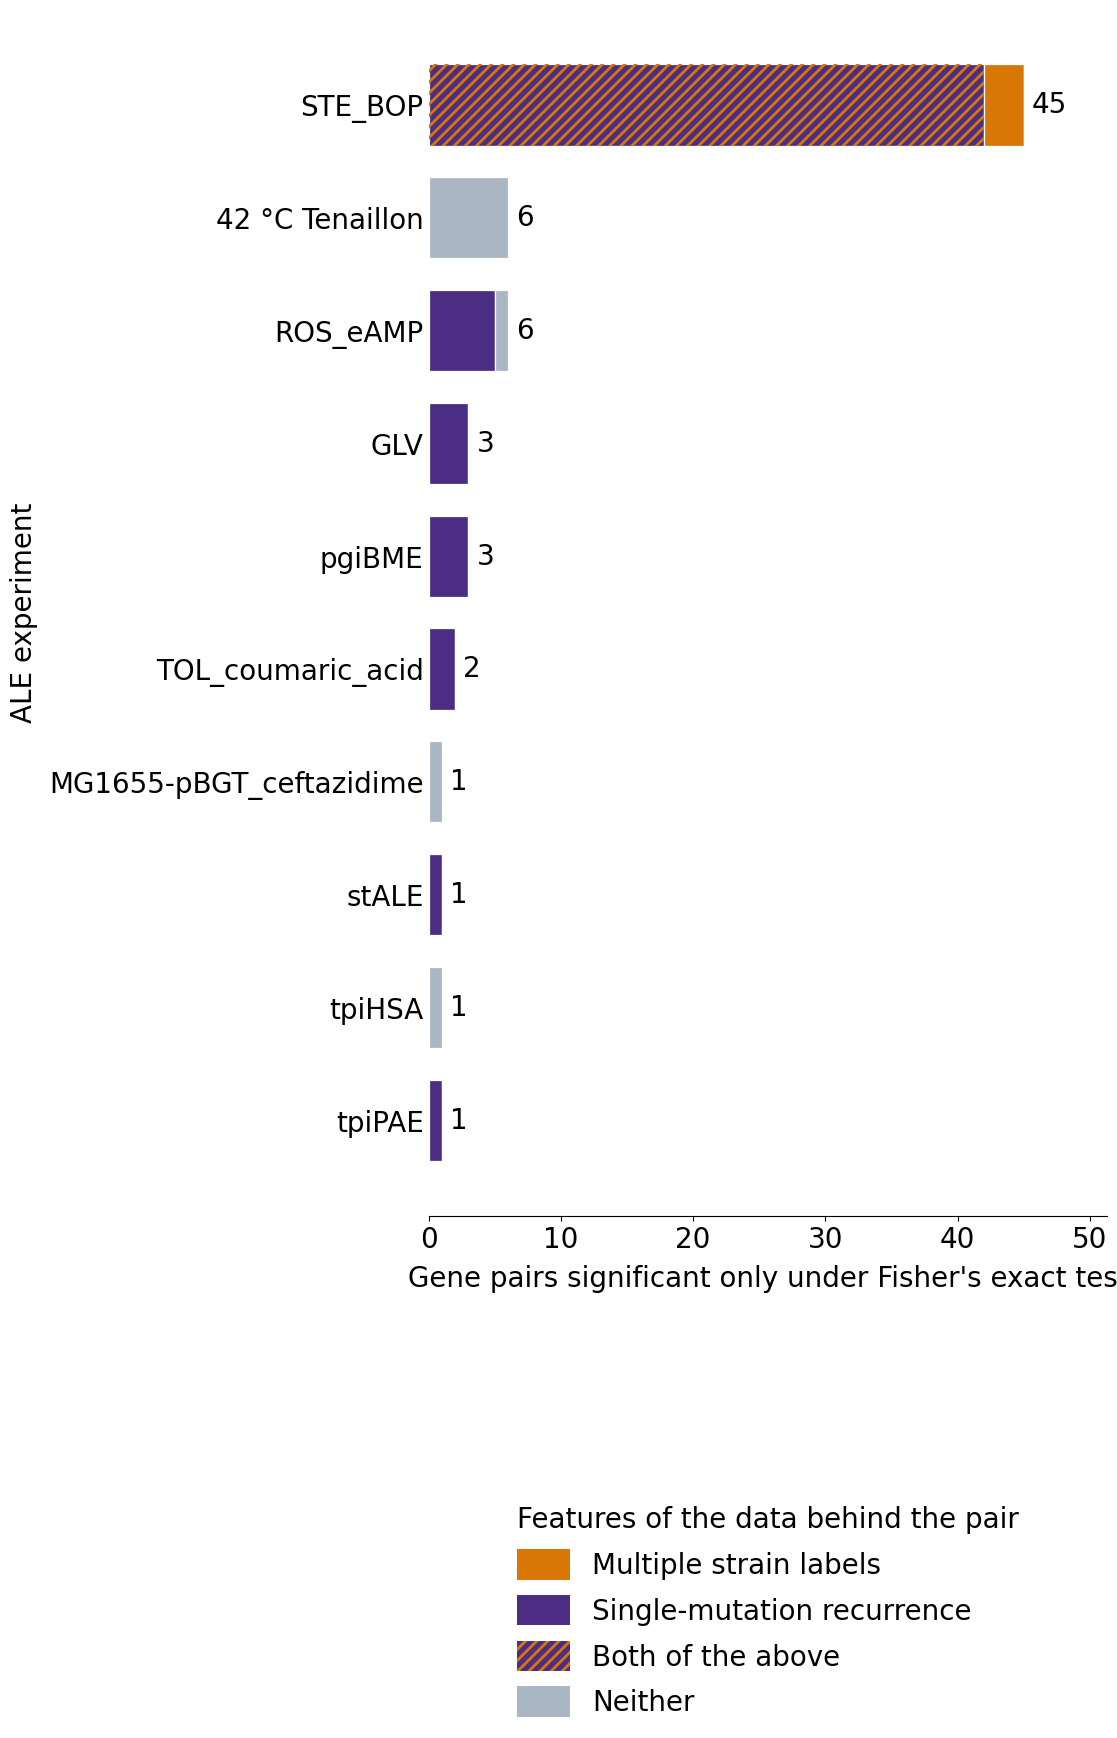

In [3]:
# ---- knobs -----------------------------------------------------------------
A_FIGSIZE  = None      # (width, height) in inches. Set it to fix the panel outright, e.g.
                       # (9.5, 7.0). None = take A_WIDTH and A_HEIGHT below.
A_WIDTH    = 11      # figure width, in inches. Wide enough for the experiment names plus the
                       # axis title centered under the axes, without the title running off the
                       # right. For a narrower panel, break the title over two lines with \n,
                       # or set it in a smaller font size.
A_HEIGHT   = 18      # figure height, in inches. None = grow with the number of bars, using
                       # A_BAR_H. Give a number to pin the panel to a fixed height instead.
A_BAR_H    = 0.46      # inches per experiment row, used only when A_HEIGHT is None
A_BAR_W    = 0.72      # bar thickness, as a fraction of the row
A_ORDER    = "count"   # "count" = most pairs first, or "name"
A_FONTSIZE = 20        # ALL text in this panel, independent of the notebook-wide FONTSIZE
A_LEG_NCOL = 1         # 1 = four rows, one per category
A_LEG_TITLE = "Features of the data behind the pair"   # None for no title
A_LEG_ORDER = ["multi", "allele", "both", "neither"]   # name the two features, then the
                       # combination, then neither, so the legend reads as a build-up. The bars
                       # stack in ORDER instead, darkest first, which is only about how they look.
A_HATCH    = True      # draw the "both" segments with their hatch
A_LEG_Y    = -0.22     # legend position below the axes (more negative pushes it further down)
A_PAD      = 1.14      # right-hand headroom for the total labels
A_PAD_IN   = 0.25      # white margin kept when saving, in inches. The axis title is centered on
                       # the axes, which sit right of center because the experiment names are long,
                       # so a tight bounding box can shave its last character.
# -----------------------------------------------------------------------------

ORDER = ["both", "multi", "allele", "neither"]
LAB = {"multi":   "Multiple strain labels",
       "allele":  "Single-mutation recurrence",
       "both":    "Both of the above",
       "neither": "Neither"}

tab = (fonly.groupby(["exp", "cat"]).size().unstack(fill_value=0)
       .reindex(columns=ORDER, fill_value=0))
tab["tot"] = tab.sum(axis=1)
tab = tab.sort_values("tot" if A_ORDER == "count" else "exp",
                      ascending=(A_ORDER != "count"))


def cat_patch(c, label=None):
    return Patch(facecolor=CAT_COL[c], label=LAB[c] if label is None else label,
                 hatch=CAT_HATCH.get(c), edgecolor=CAT_HCOL.get(c, CAT_COL[c]), linewidth=0.0)


# Draws panel A on ax: the stacked bars, each total at the end of its bar, the ticks and both axis
# titles. legend=True adds the legend with its title below the axes, as Figure_5_A shows it. The
# combined figure at the end of the notebook draws the panel with legend=False and adds the key.
def draw_panel_a(ax, legend=True):
    y = np.arange(len(tab))[::-1]
    left = np.zeros(len(tab))
    for c in ORDER:
        v = tab[c].values
        ax.barh(y, v, left=left, height=A_BAR_W, color=CAT_COL[c], edgecolor="white",
                linewidth=0.9, label=LAB[c], zorder=3)
        if A_HATCH and c in CAT_HATCH:      # second pass: hatch only, so the white separators survive
            ax.barh(y, v, left=left, height=A_BAR_W, facecolor="none", hatch=CAT_HATCH[c],
                    edgecolor=CAT_HCOL[c], linewidth=0.0, zorder=4)
        left += v
    for yi, t in zip(y, tab["tot"].values):
        ax.annotate(str(int(t)), (t, yi), textcoords="offset points", xytext=(6, 0),
                    va="center", fontsize=A_FONTSIZE, color=INK)

    ax.set_yticks(y)
    ax.set_yticklabels([short(e) for e in tab.index], fontsize=A_FONTSIZE)
    ax.set_xlabel("Gene pairs significant only under Fisher's exact test",
                  fontsize=A_FONTSIZE, color=INK, labelpad=8)
    ax.set_ylabel("ALE experiment", fontsize=A_FONTSIZE, color=INK, labelpad=8)
    ax.tick_params(axis="x", labelsize=A_FONTSIZE)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.set_xlim(0, tab["tot"].max() * A_PAD)
    ax.grid(False)

    if legend:
        leg = ax.legend(handles=[cat_patch(c) for c in A_LEG_ORDER], loc="upper center",
                        bbox_to_anchor=(0.5, A_LEG_Y), ncol=A_LEG_NCOL, fontsize=A_FONTSIZE,
                        frameon=False, handletextpad=.8, labelspacing=.55, handlelength=1.9,
                        handleheight=1.3, title=A_LEG_TITLE, alignment="left")
        if A_LEG_TITLE:
            leg.get_title().set_fontsize(A_FONTSIZE)
            leg.get_title().set_color(INK)


_a_h = A_HEIGHT if A_HEIGHT else max(3.0, len(tab) * A_BAR_H + 2.2)
fig, ax = plt.subplots(figsize=A_FIGSIZE or (A_WIDTH, _a_h))
draw_panel_a(ax)

print(tab.to_string())
tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_5_A.svg", bbox_inches="tight", pad_inches=A_PAD_IN,
                facecolor="white")
    fig.savefig(FIG_DIR / "Figure_5_A.png", dpi=DPI, bbox_inches="tight", pad_inches=A_PAD_IN,
                facecolor="white")
    print("\nwrote", (FIG_DIR / "Figure_5_A.png").relative_to(ROOT))
plt.show()

### Oncoplot helpers

Adapted from Figure 4's `onc_data` / `onc_size` / `draw_oncoplot` / `onc_report`. The main additions:
`onc_layout` can lay the endpoints out in blocks by strain annotation with a gap and a label above
each, and `draw_oncoplot` takes explicit column positions so those gaps are possible. Colors,
row order, italics and the `disp()` map are the same as in figure 4. Each panel cell records its
experiment and the arguments it gives `draw_oncoplot` in `ONC_PANELS`, so the combined figure at
the end draws the same oncoplots.

In [4]:
# Gene rows and the mutated set for one experiment. genes=None takes the genes appearing in a pair
# this experiment called significant under Fisher, most frequently mutated first, as figure 4 does.
def onc_data(exp_full, genes=None):
    auto = genes is None
    if auto:
        s = pairs[F & (pairs.exp == exp_full)]
        genes = sorted(set(s.unit1) | set(s.unit2))
    sub = cells[cells.exp == exp_full]
    hit = {g: set(sub.loc[sub.Gene_name_normalized == g, "sample_endpoint"]) for g in genes}
    if auto:
        genes = sorted(genes, key=lambda g: (-len(hit[g]), g))
    return genes, hit


# Endpoint order and column positions. EVERY endpoint of the experiment is kept either way.
#   group=False -> ordered by mutation pattern, exactly as figure 4 orders its oncoplots
#   group=True  -> the same endpoints laid out in blocks by strain annotation, separated by group_gap
#                  blank columns, returning blocks as (label, center x, n)
def onc_layout(exp_full, genes, hit, group=False, group_gap=0.9, strain_order=None):
    sub = cells[cells.exp == exp_full]
    eps = sorted(sub.sample_endpoint.unique())
    key = lambda e: (tuple(0 if e in hit[g] else 1 for g in genes), e)
    if not group:
        ep = sorted(eps, key=key)
        return ep, [float(i) for i in range(len(ep))], []

    st = strain_series(exp_full).to_dict()
    # biggest block first, ties broken alphabetically so the layout is reproducible
    # (strain_order overrides it outright)
    order = (list(strain_order) if strain_order else
             sorted(set(st.values()), key=lambda s: (-sum(v == s for v in st.values()), s)))
    unassigned = [e for e in eps if e not in st]
    ep, xpos, blocks, x = [], [], [], 0.0
    for s in order + (["unassigned"] if unassigned else []):
        blk = sorted(unassigned if s == "unassigned" else [e for e in eps if st.get(e) == s],
                     key=key)
        if not blk:
            continue
        x0 = x
        for e in blk:
            ep.append(e)
            xpos.append(x)
            x += 1.0
        blocks.append((s, (x0 + x - 1.0) / 2, len(blk)))
        x += group_gap
    return ep, xpos, blocks


def onc_size(genes, ep, xpos=None, row_h=0.30, col_w=0.42, pad_w=1.9, pad_h=0.95, blocks=()):
    span = (max(xpos) - min(xpos) + 1) if xpos else len(ep)
    return (max(3.0, span * col_w + pad_w),
            len(genes) * row_h + pad_h + (0.55 if len(blocks) else 0.0))


# blocks: (label, center, n), drawn as a name above or below its own block.  row_note: put
# note_fmt ({k} distinct mutations, {n} endpoints) to the right of each row.  Colors and
# italics are figure 4's.
def draw_oncoplot(ax, genes, ep, hit, xpos=None, blocks=(), fill=None, empty=None,
                  cell_gap=0.10, fs_gene=None, fs_xlabel=None, xlabel=None, ylabel="Gene",
                  divider=True, rules=False, row_note=False, fs_note=None, note_w=1.2,
                  note_fmt="{k}", note_color=None, shade=False, ramp=None,
                  block_pos="top", block_pad=0.95):
    fill = ONC_FILL if fill is None else fill
    empty = ONC_EMPTY if empty is None else empty
    fs_gene = FONTSIZE if fs_gene is None else fs_gene
    fs_xlabel = FONTSIZE if fs_xlabel is None else fs_xlabel
    fs_note = FONTSIZE if fs_note is None else fs_note        # same size as the gene labels
    xpos = [float(i) for i in range(len(ep))] if xpos is None else xpos
    h = cell_gap / 2
    ramp = ONC_RAMP if ramp is None else ramp
    for gi, g in enumerate(genes):
        shade_of = {}
        if shade:
            # commonest profile first, ties broken by where it first appears, so the base green
            # always marks the profile most endpoints share
            seen = [profile_of(g, e) for e in ep if e in hit[g]]
            order = sorted(set(seen), key=lambda pr: (-seen.count(pr), seen.index(pr)))
            shade_of = {pr: ramp[i % len(ramp)] for i, pr in enumerate(order)}
        for x, e in zip(xpos, ep):
            if e in hit[g]:
                col = shade_of.get(profile_of(g, e), fill) if shade else fill
            else:
                col = empty
            ax.add_patch(Rectangle((x - 0.5 + h, gi - 0.5 + h), 1 - cell_gap, 1 - cell_gap,
                                   facecolor=col, edgecolor="none"))

    blank = [x for x, e in zip(xpos, ep) if not any(e in hit[g] for g in genes)]
    if divider and blank:
        ax.axvline(min(blank) - 0.5, color=INK, lw=1.0, ls=(0, (3, 3)), zorder=4)
    if rules:
        for _lab, c, n in list(blocks)[:-1]:
            ax.axvline(c + n / 2, color=INK, lw=1.2, zorder=4)

    x_hi = max(xpos) + 0.5
    if row_note:
        for gi, g in enumerate(genes):
            k = n_distinct(g)
            ax.annotate(note_fmt.format(k=k, s="" if k == 1 else "s", n=len(hit[g])),
                        (x_hi + 0.35, gi), va="center", ha="left", fontsize=fs_note,
                        color=note_color or INK, annotation_clip=False)
        x_hi += 0.35 + note_w

    ax.set_xlim(min(xpos) - 0.5, x_hi)
    # room above the grid for the strain names, so they never sit on the axis label
    top = -0.5 - (block_pad if (len(blocks) and block_pos == "top") else 0.0)
    ax.set_ylim(len(genes) - 0.5, top)
    ax.set_yticks(range(len(genes)))
    ax.set_yticklabels([disp(g) for g in genes], fontsize=fs_gene, style="italic")
    ax.set_xticks([])
    ax.set_xlabel(f"{len(ep)} endpoints" if xlabel is None else xlabel,
                  fontsize=fs_xlabel, color=INK, labelpad=6)
    ax.set_ylabel(ylabel, fontsize=fs_xlabel, color=INK, labelpad=6)   # same size as the x title
    ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)

    for lab, c, n in blocks:                     # strain annotation beside its own block
        if block_pos == "top":
            ax.annotate(f"{lab}\n({n})", (c, -0.62), ha="center", va="bottom",
                        fontsize=fs_gene, color=INK, annotation_clip=False)
        else:
            ax.annotate(f"{lab}\n({n})", (c, len(genes) - 0.35), ha="center", va="top",
                        fontsize=fs_gene, color=INK, annotation_clip=False)


_CUR = {"exp": None}                             # set by each panel cell before it draws
# How many DISTINCT MUTATIONS a gene carries in the current experiment, read from the SAME K table
# panel A's flag is built from, so the row note and the bar can never disagree.
# Deliberately not called "alleles": the Details field also holds intergenic and noncoding entries,
# which are not alleles of the gene they are named against, so "distinct mutations" is what the
# count actually supports.
n_distinct = lambda g: k_of(_CUR["exp"], g)["al"]

# The mutation PROFILE of one cell: every mutation recorded for that gene in that endpoint, as a
# set. A gene can carry more than one mutation in the same endpoint, so the cell, not the
# mutation, is what a color can encode. Profiles need the mutations themselves, so a panel of an
# experiment in NONPUB_DIR cannot be shaded.
PROFILE = (qc.groupby(["exp", "Gene_name_normalized", "sample_endpoint"]).Details
             .apply(lambda x: tuple(sorted(set(x.astype(str).str.strip())))).to_dict())


def profile_of(g, e):
    if _CUR["exp"] in NONPUB_EXPS:
        raise ValueError(f"{_CUR['exp']}: the mutation data of this experiment are not public, so its "
                         "panel cannot be shaded (set the panel's *_SHADE knob to False)")
    return PROFILE.get((_CUR["exp"], g, e), ())
n_profiles = lambda g, eps: len({profile_of(g, e) for e in eps})


def onc_report(tag, exp_full, genes, ep, hit, blocks=()):
    cov = len({e for g in genes for e in hit[g]})
    print(f"{tag}: {len(genes)} genes, {len(ep)} endpoints, {cov} carry at least one "
          f"({len(ep) - cov} carry none)")
    st = strain_series(exp_full).to_dict()
    for lab, _c, n in blocks:
        eps = {e for e in ep if st.get(e) == lab}
        print(f"   {lab} ({n} endpoints): {[disp(g) for g in genes if hit[g] & eps]}")
    print("   " + "  ".join(f"{disp(g)} {len(hit[g])}/{n_distinct(g)}"
                            for g in genes) + "   (endpoints/distinct mutations)")


# What each oncoplot cell draws, as panel letter -> title (the experiment's name as panel A shows
# it), exp_full and kw (the arguments for draw_oncoplot), so the combined figure at the end of the
# notebook draws exactly the same panels.
ONC_PANELS = {}

### Panel B: STE_BOP, all endpoints, laid out by strain annotation

Every endpoint of the experiment is drawn, as figure 4 does. The columns are ordered into the
blocks of the strain annotations recorded in `strain_details`, with a gap and a label above each. Set
`B_GROUP = False` for figure 4's plain ordering.

STE_BOP: 16 genes, 11 endpoints, 11 carry at least one (0 carry none)
   BOP368 (3 endpoints): ['cyaA', 'fimA', 'nrdE', 'yibG', 'clpA', 'galR', 'gnd', 'sthA']
   BOP394 (4 endpoints): ['cyaA', 'fimA', 'nrdE', 'yibG', 'mdtH', 'patZ', 'ribA']
   CL4A (4 endpoints): ['mgrB', 'pflB', 'rfaI', 'ybbD', 'yecF']
   cyaA 7/1  fimA 7/1  nrdE 7/1  yibG 7/1  clpA 3/1  galR 3/3  gnd 3/2  sthA 3/3  mdtH 4/1  patZ 4/4  ribA 4/1  mgrB 4/1  pflB 4/1  rfaI 4/1  ybbD 4/1  yecF 4/1   (endpoints/distinct mutations)


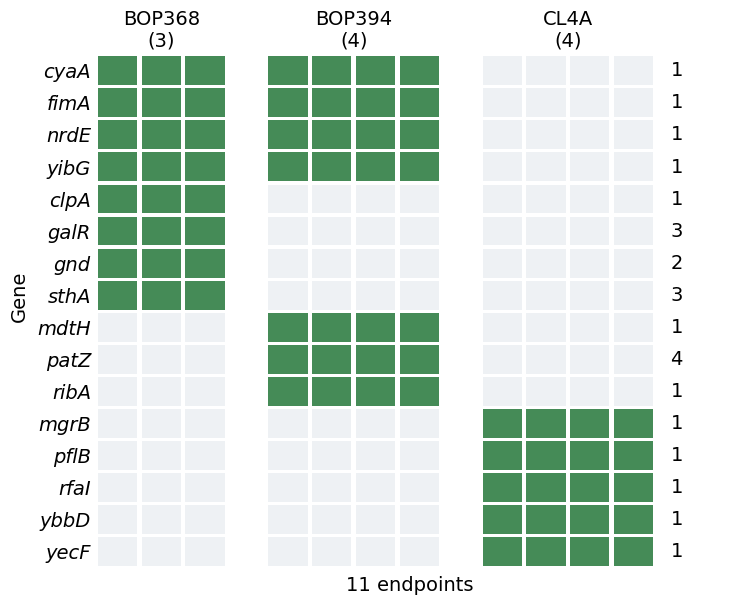

In [5]:
# ---- knobs -----------------------------------------------------------------
B_EXP       = "STE_BOP"
B_GENES     = None       # None = the genes in this experiment's Fisher-significant pairs
B_FIGSIZE   = None       # None = sized from the data, else e.g. (7.5, 5.8)
B_CELLGAP   = 0.10       # white space between cells, as a fraction of one cell
B_DIVIDER   = False      # dashed rule before the endpoints carrying none of the genes
B_GROUP     = True       # lay the columns out in blocks by strain annotation
B_GROUP_GAP = 0.9        # blank columns between blocks
B_RULES     = False      # solid rule at each boundary as well as the gap
B_ROW_NOTE  = True       # per-row note on the right
B_NOTE_FMT  = "{k}"       # bare count. Fields: {k} distinct mutations, {n} endpoints, {s} plural
B_NOTE_W    = 1.2        # room reserved for that note, in columns
B_SHADE     = False     # True shades cells by which mutations that endpoint carries
B_BLOCK_POS = "top"      # where the strain names go: "top" or "bottom"
B_ROW_ORDER = "strain"   # "strain" = group the rows by the block they belong to, else figure 4's
B_STRAIN_ORDER = ["BOP368", "BOP394", "CL4A"]   # the two BOP strains side by side, then CL4A.
                         # None = biggest block first (alphabetical on ties)
# -----------------------------------------------------------------------------

exp_full = EXP_FULL[B_EXP]
_CUR["exp"] = exp_full
genes, hit = onc_data(exp_full, B_GENES)
if B_ROW_ORDER == "strain" and B_GROUP:
    _st = strain_series(exp_full).to_dict()
    _rank = {b[0]: i for i, b in
             enumerate(onc_layout(exp_full, genes, hit, True, B_GROUP_GAP,
                                  B_STRAIN_ORDER)[2])}
    genes = sorted(genes, key=lambda g: (min([_rank.get(_st.get(e), 99) for e in hit[g]] or [99]),
                                         -len({_st.get(e) for e in hit[g]}), -len(hit[g]), g))
ep, xpos, blocks = onc_layout(exp_full, genes, hit, group=B_GROUP, group_gap=B_GROUP_GAP,
                              strain_order=B_STRAIN_ORDER)

ONC_PANELS["B"] = dict(
    title=B_EXP, exp_full=exp_full,
    kw=dict(genes=genes, ep=ep, hit=hit, xpos=xpos, blocks=blocks, cell_gap=B_CELLGAP,
            divider=B_DIVIDER, rules=B_RULES, row_note=B_ROW_NOTE,
            note_fmt=B_NOTE_FMT, note_w=B_NOTE_W, block_pos=B_BLOCK_POS,
            shade=B_SHADE,
            xlabel=f"{len(ep)} endpoints"))   # the strain grouping is described in the caption

fig, ax = plt.subplots(figsize=B_FIGSIZE or onc_size(genes, ep, xpos, blocks=blocks))
draw_oncoplot(ax, **ONC_PANELS["B"]["kw"])
onc_report(B_EXP, exp_full, genes, ep, hit, blocks)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_5_B.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_5_B.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

### Panels C and D: ROS_eAMP and GLV

Columns are ordered by mutation pattern, as in figure 4. The note to the right of each row gives
the number of distinct mutations of that gene in the experiment. Set `C_ROW_NOTE = False`
(`D_ROW_NOTE` for panel D) to drop the notes.

ROS_eAMP: 6 genes, 17 endpoints, 17 carry at least one (0 carry none)
   glnX 11/1  sucA 11/2  icd 8/3  gltA 7/1  arnA 6/1  renD 6/1   (endpoints/distinct mutations)


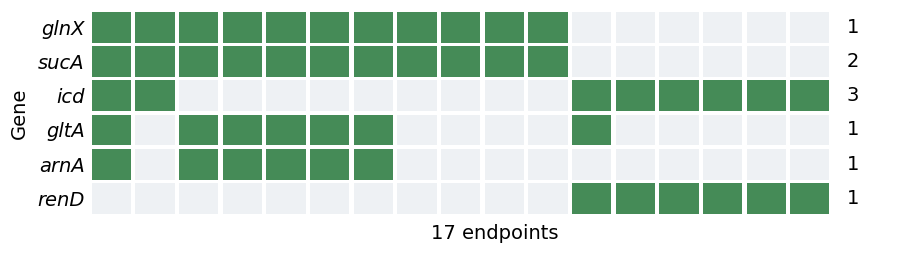

In [6]:
# ---- knobs -----------------------------------------------------------------
C_EXP      = "ROS_eAMP"
C_GENES    = None
C_FIGSIZE  = None
C_CELLGAP  = 0.10
C_DIVIDER  = False
C_ROW_NOTE = True        # note to the right of each row
C_NOTE_FMT = "{k}"        # bare count. Fields: {k} distinct mutations, {n} endpoints, {s} plural
C_NOTE_W   = 1.2         # room reserved for that note, in columns
C_SHADE    = False      # True shades cells by which mutations that endpoint carries
# -----------------------------------------------------------------------------

exp_full = EXP_FULL[C_EXP]
_CUR["exp"] = exp_full
genes, hit = onc_data(exp_full, C_GENES)
ep, xpos, _ = onc_layout(exp_full, genes, hit, group=False)

ONC_PANELS["C"] = dict(
    title=C_EXP, exp_full=exp_full,
    kw=dict(genes=genes, ep=ep, hit=hit, xpos=xpos, cell_gap=C_CELLGAP, divider=C_DIVIDER,
            row_note=C_ROW_NOTE, note_w=C_NOTE_W, note_fmt=C_NOTE_FMT,
            shade=C_SHADE))

fig, ax = plt.subplots(figsize=C_FIGSIZE or onc_size(genes, ep, xpos))
draw_oncoplot(ax, **ONC_PANELS["C"]["kw"])
onc_report(C_EXP, exp_full, genes, ep, hit)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_5_C.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_5_C.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

GLV: 3 genes, 8 endpoints, 3 carry at least one (5 carry none)
   dgcE 3/1  lpd 3/1  yfcO 3/1   (endpoints/distinct mutations)


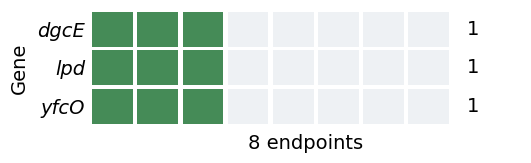

In [7]:
# ---- knobs -----------------------------------------------------------------
D_EXP      = "GLV"
D_GENES    = None
D_FIGSIZE  = None
D_CELLGAP  = 0.10
D_DIVIDER  = False
D_ROW_NOTE = True
D_NOTE_FMT = "{k}"        # bare count. Fields: {k} distinct mutations, {n} endpoints, {s} plural
D_NOTE_W   = 1.2
D_SHADE    = False      # True shades cells by which mutations that endpoint carries
# -----------------------------------------------------------------------------

exp_full = EXP_FULL[D_EXP]
_CUR["exp"] = exp_full
genes, hit = onc_data(exp_full, D_GENES)
ep, xpos, _ = onc_layout(exp_full, genes, hit, group=False)

ONC_PANELS["D"] = dict(
    title=D_EXP, exp_full=exp_full,
    kw=dict(genes=genes, ep=ep, hit=hit, xpos=xpos, cell_gap=D_CELLGAP, divider=D_DIVIDER,
            row_note=D_ROW_NOTE, note_w=D_NOTE_W, note_fmt=D_NOTE_FMT,
            shade=D_SHADE))

fig, ax = plt.subplots(figsize=D_FIGSIZE or onc_size(genes, ep, xpos))
draw_oncoplot(ax, **ONC_PANELS["D"]["kw"])
onc_report(D_EXP, exp_full, genes, ep, hit)

tight_layout_keep_axes(fig)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_5_D.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_5_D.png", dpi=DPI, bbox_inches="tight",
                facecolor="white")
plt.show()

### Key, as a separate block (figure 4 does the same)

`KEY_KW` holds the settings of the key, so the combined figure at the end draws the same key
inside panel A.

In [8]:
# ---- knobs -----------------------------------------------------------------
L_FONTSIZE  = 20        # match A_FONTSIZE if the legend sits beside panel A
L_NCOL      = 1        # 1 = one entry per row
L_FIGSIZE   = (8.0, 3.4)
L_COLSPACE  = 2.0
L_LABSPACE  = 1.0
L_HANDLEPAD = 0.8
L_MUT_LABEL = "Gene mutated in an endpoint"
L_RAMP_LABEL = "Shade marks the mutations that endpoint carries"
L_SHOW_RAMP  = False   # set True only if the panels are drawn with *_SHADE = True
L_HANDLELEN  = 1.9
# -----------------------------------------------------------------------------

ramp_handle = tuple(Patch(facecolor=c) for c in ONC_RAMP)
handles = [cat_patch(c) for c in A_LEG_ORDER] + [Patch(facecolor=ONC_FILL, label=L_MUT_LABEL)]
labels = [h.get_label() for h in handles]
hmap = {}
if L_SHOW_RAMP:
    handles.append(ramp_handle)
    labels.append(L_RAMP_LABEL)
    hmap = {ramp_handle: HandlerTuple(ndivide=len(ONC_RAMP), pad=0.12)}

KEY_KW = dict(handles=handles, labels=labels, ncol=L_NCOL, fontsize=L_FONTSIZE, frameon=False,
              handletextpad=L_HANDLEPAD, columnspacing=L_COLSPACE, labelspacing=L_LABSPACE,
              handler_map=hmap, handlelength=L_HANDLELEN)

fig = plt.figure(figsize=L_FIGSIZE)
fig.legend(loc="center", **KEY_KW)

if SAVE:
    fig.savefig(FIG_DIR / "Figure_5_key.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_5_key.png", dpi=DPI, bbox_inches="tight", facecolor="white")
    print("wrote", (FIG_DIR / "Figure_5_key.svg").relative_to(ROOT))
plt.show()

wrote figures/Figure_5/Figure_5_key.svg


<Figure size 800x340 with 0 Axes>

### Figure 5 on one canvas

Panel A on the left, with the key at its lower right, and panels B to D stacked on the right, each
in a gray box headed by its experiment's name. Every panel is drawn by the same code as its own
file. Text keeps its size in points: `A_FONTSIZE` in A, `L_FONTSIZE` in the key, and `FONTSIZE` in
B to D except their "Gene" title, which takes `FIG_GENE_FS`. Every oncoplot cell gets the same size
in inches, so the boxes set the height of the figure and panel A is stretched to that height. The
grids of B to D start at the same x. The run stops if anything does not fit: the key touching a bar
or a total, a box running into panel A, or a panel letter falling outside the canvas or onto
another element.

wrote figures/Figure_5/Figure_5.png
canvas 20.95 x 12.17 in, panel A axes 6.80 x 10.91 in
boxes: B 6.83 x 6.10 in, C 8.60 x 2.64 in, D 4.82 x 1.74 in


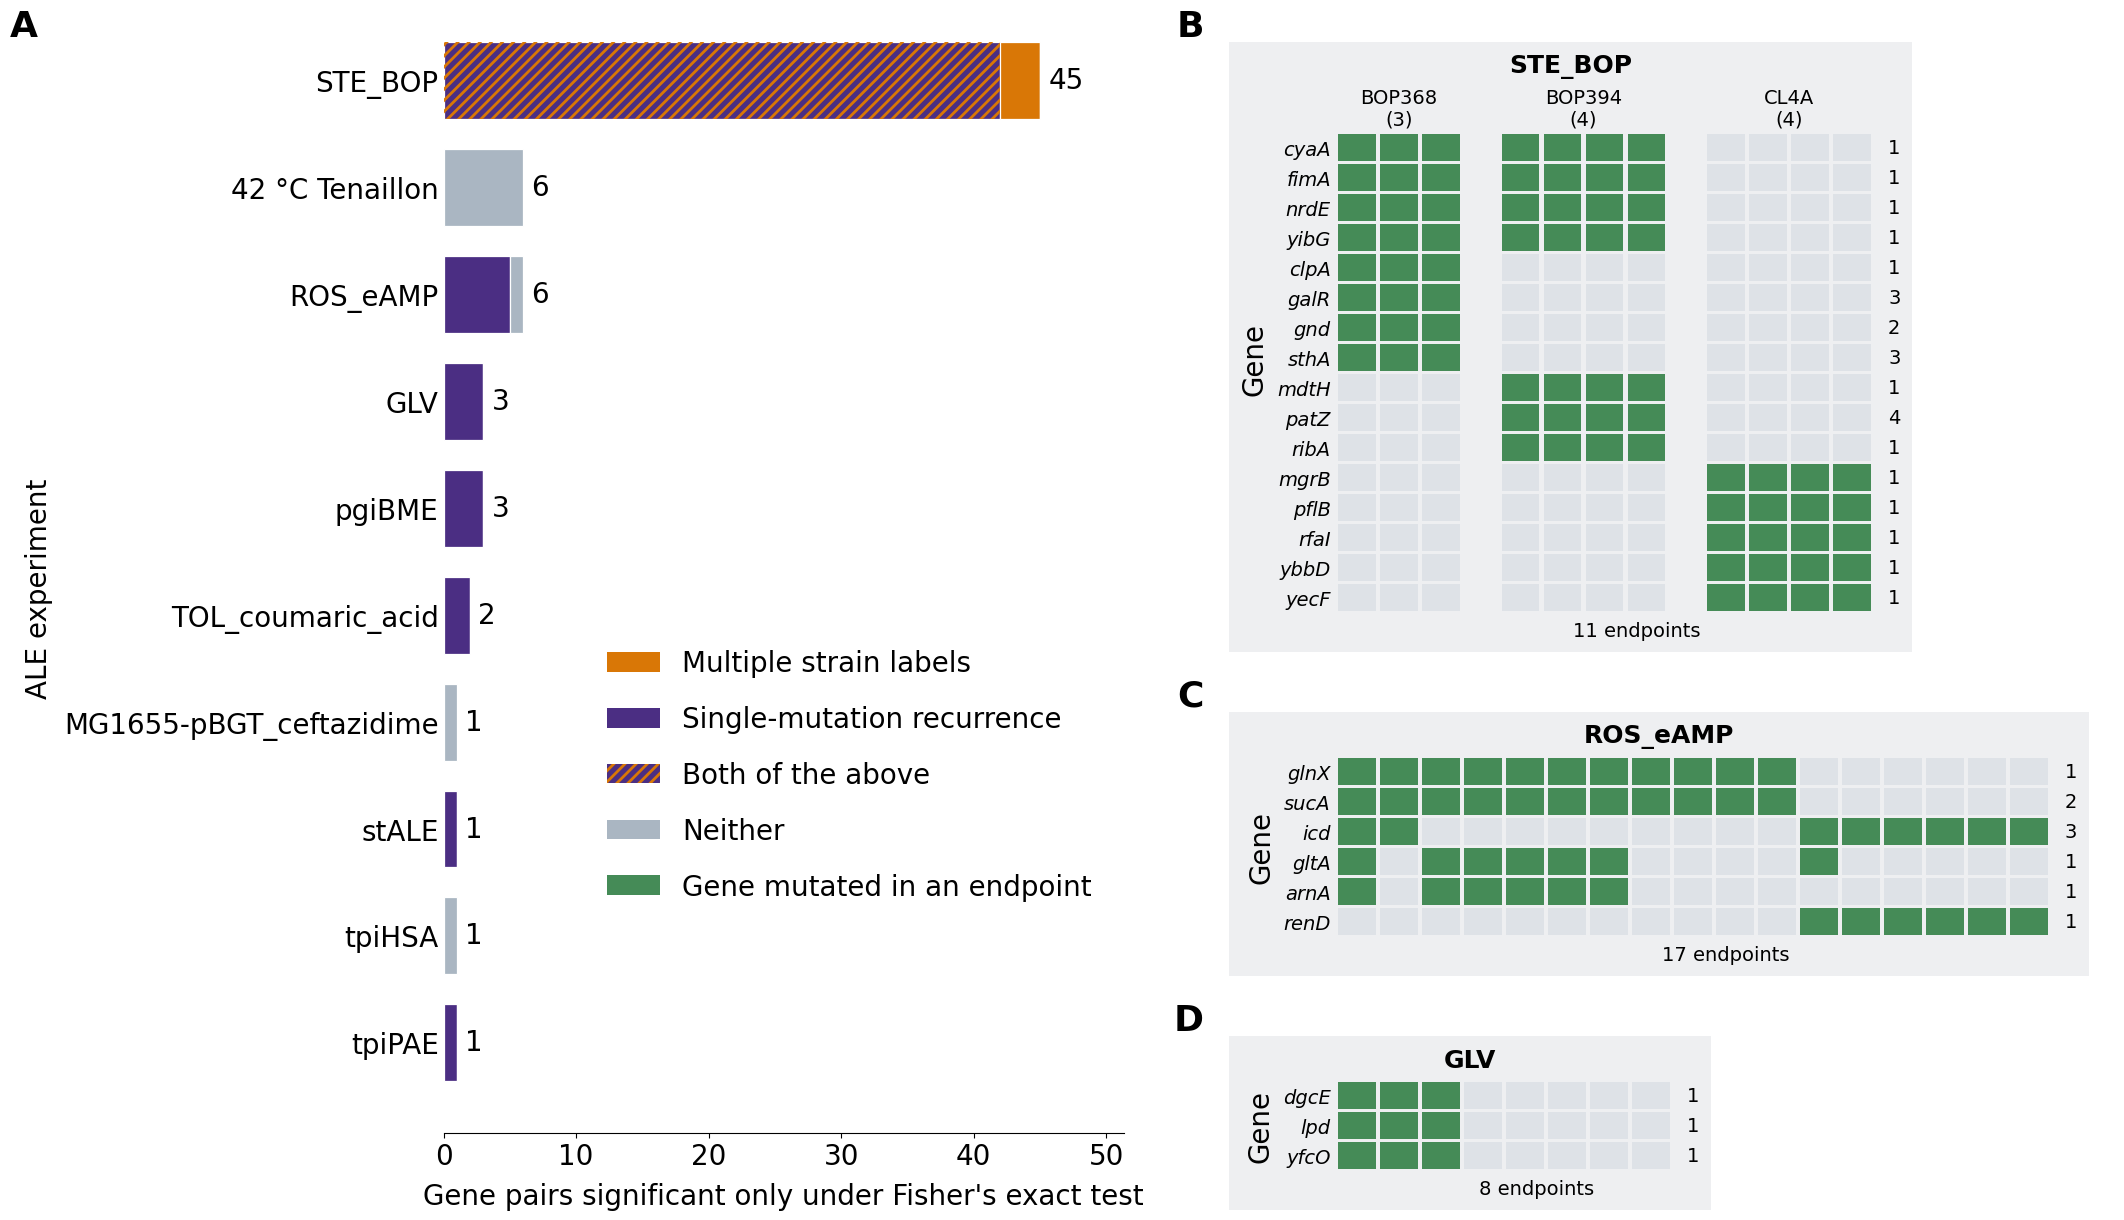

In [9]:
# ---- knobs -----------------------------------------------------------------
FIG_A_W        = 6.8        # width of panel A's axes, in inches. Its height follows from the
                            # column of boxes on the right, so that A spans the same height.
FIG_COL_W      = 0.42       # inches per endpoint column in B to D (the col_w of onc_size)
FIG_ROW_H      = 0.30       # inches per gene row in B to D (the row_h of onc_size)
FIG_GENE_FS    = A_FONTSIZE # the "Gene" title of B to D, in points. A_FONTSIZE gives it the size
                            # of A's axis titles, FONTSIZE the size it has in Figure_5_B to _D.
FIG_TITLE_FS   = 18         # experiment name at the top of each box (bold), in points
FIG_LETTER_FS  = 26         # panel letters (bold), in points
FIG_BOX_COLOR  = "#EEEFF1"  # fill of the boxes behind B to D
FIG_BOX_PAD    = 0.12       # inches between the edges of a box and its title and oncoplot
FIG_TITLE_GAP  = 0.10       # inches between a box's title and its oncoplot
FIG_BOX_GAP    = 0.60       # inches between two boxes
FIG_SAME_W     = ""         # boxes that share one width, that of the widest of them, e.g. "BC".
                            # "" = each box fits its own oncoplot.
FIG_GUTTER     = 0.85       # inches between the rightmost ink of panel A and the boxes. The
                            # letters B to D sit in this space.
FIG_KEY_ANCHOR = (0.99, 0.19)   # lower right corner of the key, as fractions of panel A's axes
                                # (0, 0 is the lower left corner of the axes)
FIG_MARGIN     = 0.08       # white margin kept around everything, in inches
# -----------------------------------------------------------------------------

# Panel letters as in Figures 1, 3 and S2: bold, each baseline PANEL_LETTER_PAD above the top of its
# panel's ink, placed from the ink measured after drawing. A sits PANEL_LETTER_LEFT left of the left
# edge of panel A's ink. B to D sit wholly left of their boxes, PANEL_LETTER_GAP from the box.
PANEL_LETTER_PAD = 0.06      # inches between the top of a panel's ink and its letter's baseline
PANEL_LETTER_LEFT = 0.15     # inches between letter A and the left edge of panel A's ink
PANEL_LETTER_GAP = 0.25      # inches between letters B to D and the left edge of their box

PANELS = ["B", "C", "D"]     # the oncoplots, top to bottom
# ONC_EMPTY is a tint chosen against white and nearly matches the box's gray. Inside a box, the
# empty cells take ONC_EMPTY multiplied by the box color, so they stand out from the box as
# ONC_EMPTY stands out from white.
EMPTY_IN_BOX = mpl.colors.to_hex(np.multiply(mpl.colors.to_rgb(ONC_EMPTY),
                                             mpl.colors.to_rgb(FIG_BOX_COLOR)))
_span = lambda lim: abs(lim[1] - lim[0])


def _place(ax, x, y, w, h):
    """Moves ax so that its lower left corner sits at x, y and its size is w x h, all in inches."""
    W, H = fig.get_size_inches()
    ax.set_position([x / W, y / H, w / W, h / H])


def _parts(ax):
    """Bounding boxes, in display pixels, of what ax draws: bars or cells, texts, the tick labels
    and title of each axis, and the visible spines."""
    arts = [ax.xaxis, ax.yaxis, *ax.patches, *ax.texts, *ax.lines,
            *(s for s in ax.spines.values() if s.get_visible())]
    boxes = [a.get_tightbbox(fig.canvas.get_renderer()) for a in arts if a.get_visible()]
    return [b for b in boxes if b is not None and np.isfinite(b.extents).all()]


def _ink(ax):
    """One box around everything ax draws, in display pixels. Unlike ax.get_tightbbox, it leaves
    out the empty parts of the axes frame."""
    return mpl.transforms.Bbox.union(_parts(ax))


def _reach(ax):
    """How far the ink of ax reaches past each edge of its axes frame, in inches, as
    (left, bottom, right, top). Negative where the ink stays inside the frame."""
    i, f = _ink(ax), ax.get_window_extent()
    return np.array([f.x0 - i.x0, f.y0 - i.y0, i.x1 - f.x1, i.y1 - f.y1]) / fig.dpi


# ---- 1. every panel drawn once, on a provisional canvas --------------------------------------
fig = plt.figure(figsize=(24, 16))           # resized in step 3
axA = fig.add_axes([0, 0, 1, 1])
draw_panel_a(axA, legend=False)
# A's axes end at the top of its first bar, so the top of the axes is the top of A's ink
axA.set_ylim(axA.get_ylim()[0], len(tab) - 1 + A_BAR_W / 2)
_key = axA.legend(loc="lower right", bbox_to_anchor=FIG_KEY_ANCHOR, **KEY_KW)
_place(axA, 6, 2, FIG_A_W, 10)               # final width, provisional height and place

onc, size = {}, {}
for p in PANELS:
    ax = fig.add_axes([0, 0, 1, 1])
    ax.patch.set_visible(False)              # the box shows between the cells
    _CUR["exp"] = ONC_PANELS[p]["exp_full"]
    draw_oncoplot(ax, empty=EMPTY_IN_BOX, **ONC_PANELS[p]["kw"])
    ax.yaxis.label.set_fontsize(FIG_GENE_FS)
    # the same size in inches for every column and every row of the three panels
    size[p] = (_span(ax.get_xlim()) * FIG_COL_W, _span(ax.get_ylim()) * FIG_ROW_H)
    _place(ax, 15, 2, *size[p])
    onc[p] = ax

title = {p: fig.text(0, 0, ONC_PANELS[p]["title"], ha="center", va="top",
                     fontsize=FIG_TITLE_FS, fontweight="bold", color=INK) for p in PANELS}
letter = {p: fig.text(0, 0, p, ha="left" if p == "A" else "right", va="baseline",
                      fontsize=FIG_LETTER_FS, fontweight="bold", color=INK) for p in "ABCD"}

# ---- 2. what the text of each panel adds around its axes, in inches ----------------------------
fig.canvas.draw()
rA = _reach(axA)
r = {p: _reach(onc[p]) for p in PANELS}
th = {p: title[p].get_window_extent().height / fig.dpi for p in PANELS}
letter_up = max(t.get_window_extent().y1 for t in letter.values()) / fig.dpi   # above the baseline

# ---- 3. the layout, in inches from the lower left corner of the canvas -------------------------
# Each box holds its title and the ink of its oncoplot, FIG_BOX_PAD from every edge, and the boxes
# stack FIG_BOX_GAP apart, all left-aligned. The grids of B to D start at the same x: each oncoplot
# is placed as if its gene names were as wide as the widest of the three. Panel A spans the same
# height: the top of its first bar is level with the top of box B, and the bottom of its x title
# with the bottom of box D.
gl = max(r[p][0] for p in PANELS)                # widest reach left of a grid (gene names, "Gene")
bw = {p: 2 * FIG_BOX_PAD + gl + size[p][0] + r[p][2] for p in PANELS}
for p in FIG_SAME_W:
    bw[p] = max(bw[q] for q in FIG_SAME_W)
bh = {p: 2 * FIG_BOX_PAD + th[p] + FIG_TITLE_GAP + r[p][3] + size[p][1] + r[p][1] for p in PANELS}
col_h = sum(bh.values()) + FIG_BOX_GAP * (len(PANELS) - 1)
a_x = FIG_MARGIN + PANEL_LETTER_LEFT + rA[0]     # lower left corner of A's axes
a_y = FIG_MARGIN + rA[1]
box_x = a_x + FIG_A_W + rA[2] + FIG_GUTTER       # left edge of every box
top = FIG_MARGIN + col_h                         # top of A's ink and of box B
W = box_x + max(bw.values()) + FIG_MARGIN
H = top + PANEL_LETTER_PAD + letter_up + FIG_MARGIN
fig.set_size_inches(W, H)

_place(axA, a_x, a_y, FIG_A_W, col_h - rA[1] - rA[3])
box, y = {}, top
for p in PANELS:
    box[p] = fig.add_artist(Rectangle((box_x / W, (y - bh[p]) / H), bw[p] / W, bh[p] / H,
                                      transform=fig.transFigure, facecolor=FIG_BOX_COLOR,
                                      edgecolor="none", zorder=-1))     # under the axes
    title[p].set_position(((box_x + bw[p] / 2) / W, (y - FIG_BOX_PAD) / H))
    ink_top = y - FIG_BOX_PAD - th[p] - FIG_TITLE_GAP
    _place(onc[p], box_x + FIG_BOX_PAD + gl, ink_top - r[p][3] - size[p][1], *size[p])
    y -= bh[p] + FIG_BOX_GAP

# ---- 4. panel letters, from the ink measured on the final layout --------------------------------
fig.canvas.draw()
_fw, _fh = fig.bbox.width, fig.bbox.height       # canvas size in display pixels
for p in letter:
    if p == "A":                                 # x is the left edge of the letter
        _b = _ink(axA)
        _x = _b.x0 / _fw - PANEL_LETTER_LEFT / W
    else:                                        # x is the right edge of the letter
        _b = box[p].get_window_extent()
        _x = _b.x0 / _fw - PANEL_LETTER_GAP / W
    letter[p].set_position((_x, _b.y1 / _fh + PANEL_LETTER_PAD / H))
fig.canvas.draw()

# ---- 5. checks. The run stops if anything does not fit ------------------------------------------
_inside = lambda b, o: o.x0 <= b.x0 and b.x1 <= o.x1 and o.y0 <= b.y0 and b.y1 <= o.y1
_hits = lambda b, others: any(b.overlaps(o) for o in others)
_pA, _kb = _parts(axA), _key.get_window_extent()
_box = {p: box[p].get_window_extent() for p in PANELS}
_let = {p: t.get_window_extent() for p, t in letter.items()}
for _what, _bbs in [("panel A", _pA), *[(f"box {p}", [_box[p]]) for p in PANELS],
                    *[(f"panel letter {p}", [_let[p]]) for p in _let]]:
    if not all(_inside(b, fig.bbox) for b in _bbs):
        raise RuntimeError(f"{_what} falls outside the canvas")
if not _inside(_kb, axA.get_window_extent()) or _hits(_kb, _pA):
    raise RuntimeError("the key leaves panel A's axes or touches a bar, a total or an axis: "
                       "change FIG_KEY_ANCHOR")
for p in PANELS:
    if not all(_inside(b, _box[p]) for b in _parts(onc[p]) + [title[p].get_window_extent()]):
        raise RuntimeError(f"panel {p} reaches outside its box")
    if _hits(_box[p], _pA + [_kb]):
        raise RuntimeError(f"box {p} overlaps panel A: widen FIG_GUTTER")
for p in _let:
    if _hits(_let[p], _pA + [_kb, *_box.values()] + [_let[q] for q in _let if q != p]):
        raise RuntimeError(f"panel letter {p} overlaps another element: widen FIG_GUTTER or "
                           "narrow PANEL_LETTER_GAP")

# ---- save ----------------------------------------------------------------------------------------
# bbox_inches is NOT "tight": the canvas is sized above, with FIG_MARGIN on every side.
if SAVE:
    _svg = FIG_DIR / "Figure_5.svg"
    fig.savefig(_svg, facecolor="white")
    fig.savefig(FIG_DIR / "Figure_5.png", dpi=DPI, facecolor="white")
    # SVG text is set to Arial, as in Figures 1, 3 and S2, so it opens in Arial in Illustrator. The
    # regex keeps any weight or style and the size, and replaces only the font family.
    _svg.write_text(re.sub(r'(font:\s*(?:[a-z]+\s+|\d+\s+)*[\d.]+px\s+)[^;"]*',
                           r'\1Arial, Helvetica, sans-serif', _svg.read_text(encoding="utf-8")),
                    encoding="utf-8")
    print("wrote", (FIG_DIR / "Figure_5.png").relative_to(ROOT))
print(f"canvas {W:.2f} x {H:.2f} in, panel A axes {FIG_A_W:.2f} x {col_h - rA[1] - rA[3]:.2f} in")
print("boxes: " + ", ".join(f"{p} {bw[p]:.2f} x {bh[p]:.2f} in" for p in PANELS))
plt.show()